# Video Game Sales Prediction on Steam Data
## Notebook 7 — Modification 4: New Pre-Release Variables

**Motivation.** Notebooks 5 and 6 improved the target and the model but kept the 42 store-page variables of
Notebook 1. The error analysis of Notebook 5 showed what those variables miss: the largest errors are
franchise titles and games from well-known studios, whose advantage is not on the store page. Both
notebooks ended with the same next step, new pre-release variables added one group at a time. Notebook 6
also noted that the closest substitute for the second parent paper's wishlist counts is how long the store
page was online before release.

**Purpose.** Four groups of new variables are added to the reference model of Notebook 5 (Gradient Boosting
on log1p(owners)), **one group at a time**, so that each group can be credited with its own effect:

| Experiment | Group added | What it measures |
|---|---|---|
| E06 | A. Studio experience | How many games the developer and the publisher released before this one |
| E07 | B. Franchise and title | Whether the title marks a sequel or continues an earlier series |
| E08 | C. Store-page lead time | How long the store page existed before release |
| E09 | D. Store-page extras | Website, support contact, English support, release-week competition |
| E10 | Past sales (sensitivity only) | How well the developer's and publisher's earlier games sold |

**Rules fixed before running the experiments.**
- **Protocol:** the training set, folds and log1p(owners) target of Notebooks 5 and 6. The test set is used
  once, for the adopted model.
- **Adoption:** a group is kept only if it raises cross-validated R² (log) by at least 0.01. Each step starts
  from the last adopted set.
- **Pre-release only:** every variable in groups A–D must be known on the release date (Table 29).
- **Past sales are kept out of the main model.** The owner counts of a studio's earlier games are a 2025
  snapshot, so they include sales made after the game being predicted came out. They are tested separately
  (E10), on a chronological split only.

**Questions.**
1. Which groups of new pre-release variables improve predictions for unseen games?
2. How well does the model forecast games released after its training data ends?
3. How much would a studio's past sales add, if they could be used?

The same experiments are recorded as E06–E10 in `experiments/EXPERIMENT_LOG.md`.

In [1]:
import json
import os

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, train_test_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
RANDOM_STATE = 42

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
FEATURES = spec["numeric"] + spec["genres"] + spec["categories"]
data["owners"] = (data["owners_millions"] * 1e6).round()   # midpoint of the SteamSpy owner range
print(f"Modeling table from Notebook 1: {len(data):,} games, {len(FEATURES)} features")

C:\Users\Nobutaka\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modeling table from Notebook 1: 76,727 games, 42 features


---
# 12. Modification 4: New Pre-Release Variables

## 12.1 Building the new variables

The modeling table of Notebook 1 has no developer, publisher or title information, so the new variables are
built here from the raw `games.json` (same pinned version 49) and joined to the modeling table by AppID.
Notebooks 1–6 and their outputs are unchanged.

Earlier releases are counted over **all standalone games**, with or without an owner label, because a
studio's release history is public whether or not SteamSpy tracked the game.

In [2]:
path = kagglehub.dataset_download("fronkongames/steam-games-dataset/versions/49")
with open(os.path.join(path, "games.json"), encoding="utf-8") as f:
    raw_json = json.load(f)
apps = pd.DataFrame([{
    "appid": int(appid), "name": v.get("name"), "release_date": v.get("release_date"),
    "developers": v.get("developers") or [], "publishers": v.get("publishers") or [],
    "genres": v.get("genres") or [], "supported_languages": v.get("supported_languages") or [],
    "website": v.get("website") or "", "support_email": v.get("support_email") or "",
    "support_url": v.get("support_url") or "",
} for appid, v in raw_json.items()])
del raw_json
apps["release_dt"] = pd.to_datetime(apps["release_date"], errors="coerce", format="mixed")

# Standalone games, defined as in Notebook 1 (Section 2.5): playtests, demos and software are removed
is_test_build = apps["name"].fillna("").str.lower().str.contains(r"\bplaytest\b|\bdemo\b")
SOFTWARE_GENRES = {"Utilities", "Design & Illustration", "Animation & Modeling", "Video Production",
                   "Game Development", "Photo Editing", "Audio Production", "Software Training",
                   "Web Publishing", "Accounting"}
GAME_GENRES = {"Action", "Adventure", "Casual", "RPG", "Simulation", "Strategy", "Sports", "Racing",
               "Massively Multiplayer"}
is_software = apps["genres"].apply(lambda L: bool(SOFTWARE_GENRES & set(L)) and not (GAME_GENRES & set(L)))
pool = apps[~is_test_build & ~is_software].copy().reset_index(drop=True)
pool["developer"] = pool["developers"].apply(lambda L: L[0] if L else None)
pool["publisher"] = pool["publishers"].apply(lambda L: L[0] if L else None)
print(f"Applications: {len(apps):,} | standalone games used for counting earlier releases: {len(pool):,} "
      f"| of which in the modeling table: {pool['appid'].isin(data['appid']).sum():,}")

Applications: 141,900 | standalone games used for counting earlier releases: 132,243 | of which in the modeling table: 76,727


**Group A: studio experience.** The number of games the developer and the publisher released before this
one, whether this is the developer's first game on Steam, whether the developer published the game itself,
and the number of developers listed. Only releases dated strictly before the game's own release date are
counted. Counts are log-transformed for Linear Regression; Gradient Boosting is unaffected by this.

In [3]:
def prior_release_count(keys):
    """Number of pool games with the same key(s) and a strictly earlier release date. Games released on
    the same day never count each other."""
    keys = [keys] if isinstance(keys, str) else keys
    per_day = pool.dropna(subset=keys).groupby(keys + ["release_dt"]).size().rename("n").reset_index()
    per_day = per_day.sort_values(keys + ["release_dt"])
    per_day["prior"] = per_day.groupby(keys)["n"].cumsum() - per_day["n"]
    out = pool[keys + ["release_dt"]].merge(per_day[keys + ["release_dt", "prior"]], on=keys + ["release_dt"], how="left")
    return out["prior"].fillna(0).to_numpy()


pool["dev_prior_releases"] = prior_release_count("developer")
pool["pub_prior_releases"] = prior_release_count("publisher")
pool["log_dev_prior_releases"] = np.log1p(pool["dev_prior_releases"])
pool["log_pub_prior_releases"] = np.log1p(pool["pub_prior_releases"])
pool["dev_debut"] = (pool["dev_prior_releases"] == 0).astype(int)
pool["self_published"] = [int(bool(d) and set(d) == set(p)) for d, p in zip(pool["developers"], pool["publishers"])]
pool["n_developers"] = pool["developers"].str.len()
GROUP_A = ["log_dev_prior_releases", "log_pub_prior_releases", "dev_debut", "self_published", "n_developers"]

**Group B: franchise and title.** A sequel marker (a number or Roman numeral at the end of the title or
before a subtitle), a subtitle, the number of words in the title, and the number of earlier games with the
same title stem from the same developer or publisher (the larger of the two counts).

In [4]:
title = pool["name"].fillna("")
NUMERAL = r"(?:[2-9]|1[0-9]|II|III|IV|V|VI|VII|VIII|IX|X)"
pool["has_sequel_marker"] = title.str.contains(rf"(?:\s|^){NUMERAL}(?:\s*$|\s*:|\s+-\s)").astype(int)
pool["has_subtitle"] = title.str.contains(r":|\s-\s").astype(int)
pool["title_words"] = title.str.split().str.len()

# Title stem: the part before a subtitle, without a trailing number ("Sniper Elite 4" -> "sniperelite")
stem = title.str.split(r":|\s-\s", regex=True).str[0]
stem = stem.str.replace(rf"\s+(?:[0-9]+|{NUMERAL})\s*$", "", regex=True)
stem = stem.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
pool["title_stem"] = stem.where(stem.str.len() >= 4)   # very short stems are too ambiguous to match
pool["franchise_prior_entries"] = np.maximum(prior_release_count(["title_stem", "developer"]),
                                             prior_release_count(["title_stem", "publisher"]))
pool["log_franchise_prior_entries"] = np.log1p(pool["franchise_prior_entries"])
GROUP_B = ["has_sequel_marker", "has_subtitle", "title_words", "log_franchise_prior_entries"]

**Group C: store-page lead time.** A longer time between the creation of the store page and release gives a
game more time to collect attention and wishlists. The creation date is not in the dataset, so it is
estimated from the AppID. Steam assigns AppIDs in increasing order when a page is registered, and no game
is released before its page exists, so the earliest release dates among the next 1,000 AppIDs (their 2nd
percentile) date the page. Lead time is the release date minus this estimate. Values below −30 days are
re-releases that kept an older release date and are flagged as missing. All 141,900 applications are used
for the estimate; no owner information is involved.

In [5]:
seq = apps[["appid", "release_dt"]].dropna().sort_values("appid").reset_index(drop=True)
days = (seq["release_dt"] - pd.Timestamp("1970-01-01")).dt.days.astype(float)
forward_low = days[::-1].rolling(1000, min_periods=50).quantile(0.02)[::-1]   # 2nd percentile of the next 1,000 AppIDs
created = forward_low[::-1].cummin()[::-1]                                     # made non-decreasing in AppID
seq["page_created_est"] = pd.Timestamp("1970-01-01") + pd.to_timedelta(created, unit="D")
pool = pool.merge(seq[["appid", "page_created_est"]], on="appid", how="left")

lead = (pool["release_dt"] - pool["page_created_est"]).dt.days
lead = lead.where(lead >= -30).clip(lower=0)     # below -30 days: re-release that kept an older date -> missing
pool["lead_missing"] = lead.isna().astype(int)
pool["lead_days"] = lead.fillna(0)
pool["log_lead_days"] = np.log1p(pool["lead_days"])
GROUP_C = ["log_lead_days", "lead_missing"]

**Group D: store-page extras.** Whether the page lists an official website, a support contact and English
among its languages, and how many standalone games were released in the same week.

In [6]:
pool["has_website"] = (pool["website"].str.len() > 0).astype(int)
pool["has_support_contact"] = ((pool["support_email"].str.len() > 0) | (pool["support_url"].str.len() > 0)).astype(int)
pool["has_english"] = pool["supported_languages"].apply(lambda L: int(any("English" in x for x in L)))
week = pool["release_dt"].dt.to_period("W")
pool["same_week_releases"] = week.map(week.value_counts())
pool["log_same_week_releases"] = np.log1p(pool["same_week_releases"])
GROUP_D = ["has_website", "has_support_contact", "has_english", "log_same_week_releases"]

**Past sales (sensitivity experiment E10 only).** The mean and the best log owner count among the
developer's, and the publisher's, earlier labeled games. They are missing for a studio with no earlier
labeled game; Gradient Boosting handles missing values directly.

In [7]:
pool["log_owners"] = np.log1p(pool["appid"].map(data.set_index("appid")["owners"]))   # labeled games only


def prior_sales(key):
    """Mean and maximum of log1p(owners) over the labeled games with the same key released strictly earlier."""
    labeled = pool.dropna(subset=[key, "log_owners"])
    per_day = labeled.groupby([key, "release_dt"])["log_owners"].agg(n="size", total="sum", top="max").reset_index()
    per_day = per_day.sort_values("release_dt")
    by_key = per_day.groupby(key)
    per_day["cum_n"], per_day["cum_total"] = by_key["n"].cumsum(), by_key["total"].cumsum()
    per_day["cum_top"] = by_key["top"].cummax()
    left = pool[[key, "release_dt"]].reset_index().dropna(subset=[key]).sort_values("release_dt")
    # allow_exact_matches=False: only release dates strictly before the game's own date are matched
    m = pd.merge_asof(left, per_day[[key, "release_dt", "cum_n", "cum_total", "cum_top"]], on="release_dt",
                      by=key, allow_exact_matches=False).set_index("index").reindex(pool.index)
    return m["cum_total"] / m["cum_n"], m["cum_top"]


pool["dev_prior_mean_log_owners"], pool["dev_prior_max_log_owners"] = prior_sales("developer")
pool["pub_prior_mean_log_owners"], pool["pub_prior_max_log_owners"] = prior_sales("publisher")
PAST_SALES = ["dev_prior_mean_log_owners", "dev_prior_max_log_owners",
              "pub_prior_mean_log_owners", "pub_prior_max_log_owners"]

In [8]:
GROUPS = {"A. Studio experience": GROUP_A, "B. Franchise and title": GROUP_B,
          "C. Store-page lead time": GROUP_C, "D. Store-page extras": GROUP_D}
NEW = [c for cols in GROUPS.values() for c in cols]
HELPERS = ["dev_prior_releases", "pub_prior_releases", "franchise_prior_entries", "lead_days", "same_week_releases"]

n_rows = len(data)
data = data.merge(pool[["appid"] + NEW + PAST_SALES + HELPERS], on="appid", how="left", validate="one_to_one")
assert len(data) == n_rows and data[NEW].isna().sum().sum() == 0     # left merge keeps the row order of Notebook 1

data[["appid"] + NEW + PAST_SALES + HELPERS].to_csv(os.path.join(DATA_DIR, "engineered_features.csv.gz"), index=False)
with open(os.path.join(DATA_DIR, "engineered_features.json"), "w") as f:
    json.dump({**GROUPS, "Past sales (sensitivity only)": PAST_SALES}, f, indent=2)

has_past = data[["dev_prior_mean_log_owners", "pub_prior_mean_log_owners"]].notna().any(axis=1)
print(f"New variables: {len(NEW)} in four groups, plus {len(PAST_SALES)} past-sales variables")
print(f"Developer's first game on Steam: {data['dev_debut'].mean():.1%} | self-published: {data['self_published'].mean():.1%} "
      f"| sequel marker: {data['has_sequel_marker'].mean():.1%} | earlier game with the same title stem: "
      f"{(data['franchise_prior_entries'] > 0).mean():.1%}")
print(f"Store-page lead time: median {data.loc[data['lead_missing'] == 0, 'lead_days'].median():.0f} days, "
      f"missing for {data['lead_missing'].mean():.1%}")
print(f"Games whose developer or publisher has an earlier labeled game (past sales available): {has_past.mean():.1%}")

New variables: 15 in four groups, plus 4 past-sales variables
Developer's first game on Steam: 60.0% | self-published: 68.5% | sequel marker: 4.9% | earlier game with the same title stem: 7.1%
Store-page lead time: median 56 days, missing for 0.6%
Games whose developer or publisher has an earlier labeled game (past sales available): 48.2%


## 12.2 Leakage audit and first look

Table 29 applies the rule of Notebook 1 (Section 2.6) to each new variable: it may be used only if its value
is known on the release date. Table 30 then describes owners by level of selected new variables, in the
second parent paper's format.

In [9]:
audit = pd.DataFrame([
    ("A", "Earlier releases by the developer / publisher (log)", "Developer, publisher, release dates",
     "Counts only games dated strictly before this game's release."),
    ("A", "Developer's first game; self-published; number of developers", "Developer, publisher",
     "Fixed when the store page is created."),
    ("B", "Sequel marker; subtitle; words in title", "Title", "The title is public before release."),
    ("B", "Earlier games with the same title stem (log)", "Title, developer, publisher, release dates",
     "Counts only games dated strictly before this game's release."),
    ("C", "Store-page lead time in days (log); missing flag", "AppID order, release date",
     "The page exists before release. Its creation date is estimated, not observed."),
    ("D", "Website; support contact; English supported", "Store-page fields",
     "Entered for release, but read at the 2025 snapshot and may have been edited since."),
    ("D", "Games released in the same week (log)", "Release dates", "Release schedules are public."),
    ("Past sales", "Mean and best log owners of the developer's / publisher's earlier games",
     "Owner estimates of earlier games",
     "Only partly: the owner counts are a 2025 snapshot and include sales made after this game's release. "
     "Used in the sensitivity experiment only (Section 12.5)."),
], columns=["Group", "Variable", "Built from", "Known before release?"])
audit.to_csv(os.path.join(TAB_DIR, "table29_new_variable_audit.csv"), index=False)
audit.style.hide(axis="index").set_caption("Table 29. New variables and why each is available before release")

Group,Variable,Built from,Known before release?
A,Earlier releases by the developer / publisher (log),"Developer, publisher, release dates",Counts only games dated strictly before this game's release.
A,Developer's first game; self-published; number of developers,"Developer, publisher",Fixed when the store page is created.
B,Sequel marker; subtitle; words in title,Title,The title is public before release.
B,Earlier games with the same title stem (log),"Title, developer, publisher, release dates",Counts only games dated strictly before this game's release.
C,Store-page lead time in days (log); missing flag,"AppID order, release date","The page exists before release. Its creation date is estimated, not observed."
D,Website; support contact; English supported,Store-page fields,"Entered for release, but read at the 2025 snapshot and may have been edited since."
D,Games released in the same week (log),Release dates,Release schedules are public.
Past sales,Mean and best log owners of the developer's / publisher's earlier games,Owner estimates of earlier games,Only partly: the owner counts are a 2025 snapshot and include sales made after this game's release. Used in the sensitivity experiment only (Section 12.5).


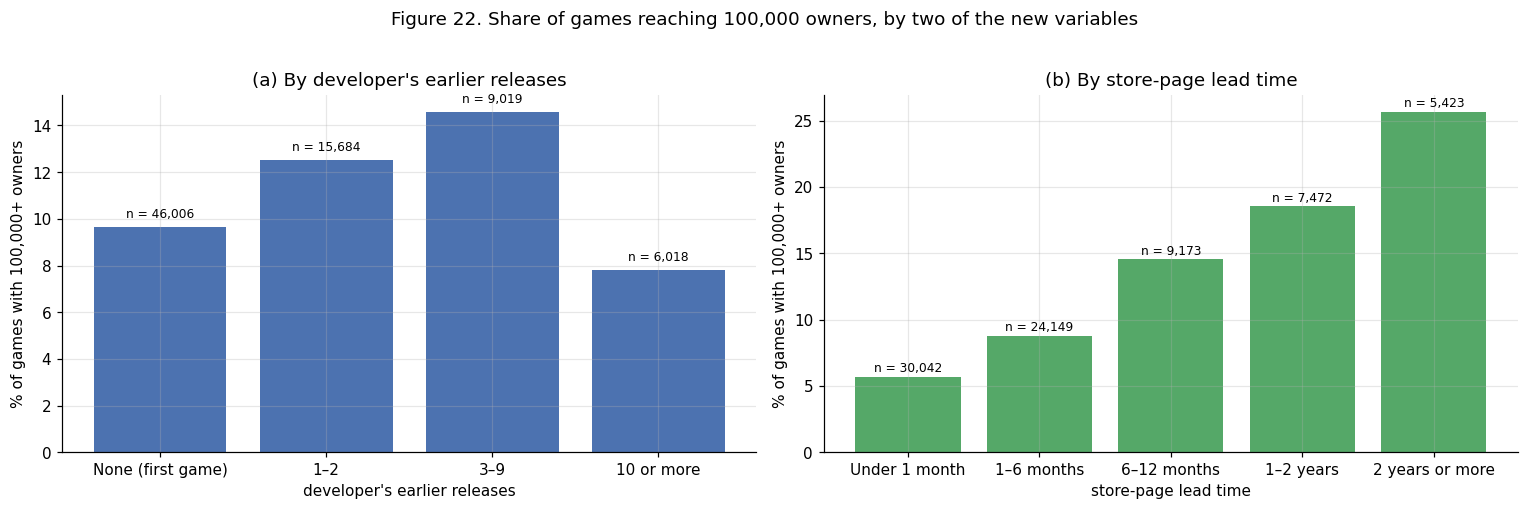

In [10]:
data["Developer's earlier releases"] = pd.cut(data["dev_prior_releases"], [-1, 0, 2, 9, np.inf],
                                              labels=["None (first game)", "1–2", "3–9", "10 or more"])
LEAD_LABELS = ["Under 1 month", "1–6 months", "6–12 months", "1–2 years", "2 years or more"]
data["Store-page lead time"] = pd.cut(data["lead_days"].where(data["lead_missing"] == 0),
                                      [-1, 29, 182, 364, 729, np.inf], labels=LEAD_LABELS)
data["Publishing"] = np.where(data["self_published"] == 1, "Self-published", "Separate publisher")
data["Sequel marker in title"] = np.where(data["has_sequel_marker"] == 1, "Yes", "No")
data["Official website listed"] = np.where(data["has_website"] == 1, "Yes", "No")


def describe(key):
    g = data.groupby(key, observed=True)["owners"]
    return pd.DataFrame({"Games": g.size(), "Mean owners": g.mean(), "Median owners": g.median(),
                         "Share with 100k+ owners": g.apply(lambda s: (s >= 1e5).mean())})


DESCRIBED = ["Developer's earlier releases", "Publishing", "Sequel marker in title", "Store-page lead time",
             "Official website listed"]
table30 = pd.concat({k: describe(k) for k in DESCRIBED}, names=["Variable", "Level"])
table30.to_csv(os.path.join(TAB_DIR, "table30_new_variables_descriptive.csv"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, key, color, panel in [(axes[0], "Developer's earlier releases", BLUE, "(a)"),
                              (axes[1], "Store-page lead time", GREEN, "(b)")]:
    t = table30.loc[key]
    ax.bar(t.index.astype(str), 100 * t["Share with 100k+ owners"], color=color)
    for i, (share, n) in enumerate(zip(t["Share with 100k+ owners"], t["Games"])):
        ax.text(i, 100 * share + 0.4, f"n = {n:,}", ha="center", fontsize=8)
    ax.set_ylabel("% of games with 100,000+ owners")
    ax.set_xlabel(key.lower())
    ax.set_title(f"{panel} By {key.lower()}")
fig.suptitle("Figure 22. Share of games reaching 100,000 owners, by two of the new variables", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig22_new_variables.png"), dpi=150, bbox_inches="tight")
plt.show()
table30.style.format({"Games": "{:,}", "Mean owners": "{:,.0f}", "Median owners": "{:,.0f}",
                      "Share with 100k+ owners": "{:.1%}"}).set_caption(
    "Table 30. Owners by level of selected new variables (the second parent paper's descriptive format)")

**Interpretation.** These are raw comparisons; nothing else is held fixed.
- **Most games are a developer's first.** 60.0% of games are their developer's first release on Steam, and
  9.7% of them reach 100,000 owners. The share rises to 12.5% with 1–2 earlier releases and 14.6% with 3–9,
  then falls to 7.8% for developers with 10 or more, a group that includes studios releasing many small games.
- **A separate publisher goes with higher sales.** 17.3% of games with a separate publisher reach 100,000
  owners, against 7.7% of self-published games.
- **Sequels sell more, but they are rare.** 22.0% of titles with a sequel marker reach 100,000 owners, against
  10.1% of the others, but only 4.9% of games have one.
- **Lead time shows the clearest pattern (Figure 22b).** The share reaching 100,000 owners rises at every
  step, from 5.7% for pages created under a month before release to 25.7% for pages online two years or more.
  Mean owners rise tenfold, from 44,040 to 441,296.
- **Games with an official website** reach 100,000 owners almost three times as often (16.1% against 5.6%).

## 12.3 Adding one group at a time (E06–E09)

Each experiment adds one group to the last adopted set and repeats the 5-fold cross-validation of Notebook 5
with Gradient Boosting at default settings. Linear Regression is fitted on the same variables for reference.
"Folds improved" counts the folds, out of five, in which the new set scores higher than the set it is
compared with.

In [11]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train))
gradient_boosting = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
linear_regression = LinearRegression()


def scores(owners, pred_log):
    """R² and MAE on the log scale, and MAE in millions of owners after converting back with expm1."""
    y_log = np.log1p(owners)
    return {"R2 (log)": r2_score(y_log, pred_log), "MAE (log)": mean_absolute_error(y_log, pred_log),
            "MAE (millions)": mean_absolute_error(owners / 1e6, np.expm1(pred_log) / 1e6)}


def fit_predict(model, features, fit_frame, predict_frame):
    fitted = clone(model).fit(fit_frame[features], np.log1p(fit_frame["owners"]))
    return fitted, fitted.predict(predict_frame[features])


def cross_validate(model, features, fold_list=folds):
    """Per-fold validation scores and out-of-fold predictions (log scale) on the training set."""
    oof, rows = np.zeros(len(train)), []
    for tr, va in fold_list:
        _, oof[va] = fit_predict(model, features, train.iloc[tr], train.iloc[va])
        rows.append(scores(train["owners"].to_numpy()[va], oof[va]))
    return pd.DataFrame(rows), oof

Adopted: A. Studio experience, C. Store-page lead time -> 49 variables, CV R² (log) 0.460 ± 0.009


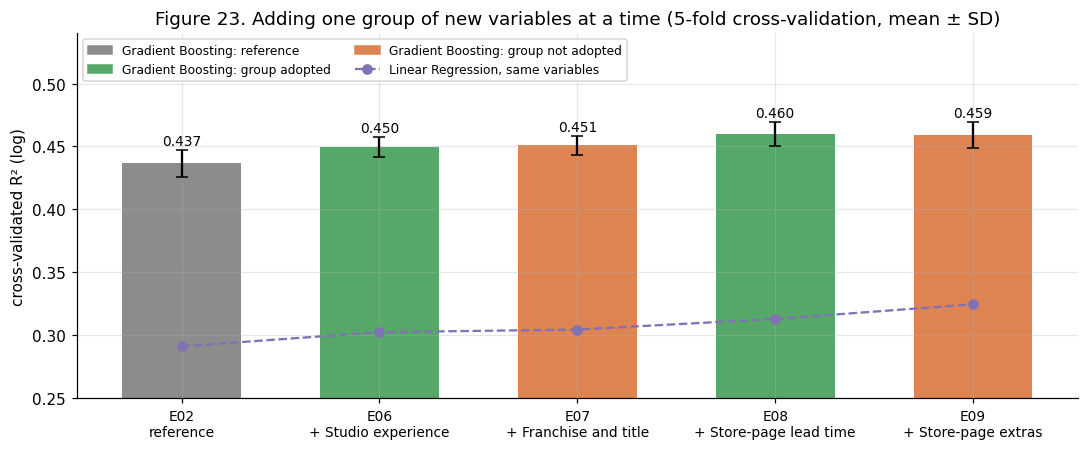

,Variables added,Variables,CV R² (log),SD,Gain,Folds improved,Decision,CV MAE (millions),Linear Regression CV R² (log)
Experiment,,,,,,,,,
E02 (reference),— (42 variables of Notebook 1),42,0.437,0.011,,,reference,0.104,0.291
E06,A. Studio experience,47,0.450,0.008,+0.013,5 of 5,adopted,0.103,0.302
E07,B. Franchise and title,51,0.451,0.008,+0.001,3 of 5,not adopted,0.103,0.304
E08,C. Store-page lead time,49,0.460,0.009,+0.010,5 of 5,adopted,0.102,0.313
E09,D. Store-page extras,53,0.459,0.011,-0.001,2 of 5,not adopted,0.103,0.325


In [12]:
THRESHOLD = 0.01   # minimum gain in cross-validated R² (log) for a group to be adopted; fixed in advance

reference, reference_oof = cross_validate(gradient_boosting, FEATURES)
reference_lr, _ = cross_validate(linear_regression, FEATURES)
rows = [{"Experiment": "E02 (reference)", "Variables added": "— (42 variables of Notebook 1)", "Variables": len(FEATURES),
         "CV R² (log)": reference["R2 (log)"].mean(), "SD": reference["R2 (log)"].std(), "Gain": np.nan,
         "Folds improved": "", "Decision": "reference", "CV MAE (millions)": reference["MAE (millions)"].mean(),
         "Linear Regression CV R² (log)": reference_lr["R2 (log)"].mean()}]

adopted, adopted_cv, adopted_oof, adopted_groups = list(FEATURES), reference, reference_oof, []
for exp_id, (group, columns) in zip(["E06", "E07", "E08", "E09"], GROUPS.items()):
    candidate = adopted + columns
    cv, oof = cross_validate(gradient_boosting, candidate)
    cv_lr, _ = cross_validate(linear_regression, candidate)
    gain = cv["R2 (log)"].mean() - adopted_cv["R2 (log)"].mean()
    keep = gain >= THRESHOLD
    rows.append({"Experiment": exp_id, "Variables added": group, "Variables": len(candidate),
                 "CV R² (log)": cv["R2 (log)"].mean(), "SD": cv["R2 (log)"].std(), "Gain": gain,
                 "Folds improved": f"{(cv['R2 (log)'] > adopted_cv['R2 (log)']).sum()} of 5",
                 "Decision": "adopted" if keep else "not adopted",
                 "CV MAE (millions)": cv["MAE (millions)"].mean(),
                 "Linear Regression CV R² (log)": cv_lr["R2 (log)"].mean()})
    if keep:
        adopted, adopted_cv, adopted_oof = candidate, cv, oof
        adopted_groups.append(group)
table31 = pd.DataFrame(rows).set_index("Experiment")
table31.to_csv(os.path.join(TAB_DIR, "table31_new_variables_cv.csv"))
print(f"Adopted: {', '.join(adopted_groups)} -> {len(adopted)} variables, "
      f"CV R² (log) {adopted_cv['R2 (log)'].mean():.3f} ± {adopted_cv['R2 (log)'].std():.3f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(table31))
colors = [GREY] + [GREEN if d == "adopted" else ORANGE for d in table31["Decision"][1:]]
ax.bar(x, table31["CV R² (log)"], yerr=table31["SD"], color=colors, capsize=4, width=0.6)
for xi, v, s in zip(x, table31["CV R² (log)"], table31["SD"]):
    ax.text(xi, v + s + 0.004, f"{v:.3f}", ha="center", fontsize=9)
ax.plot(x, table31["Linear Regression CV R² (log)"], "o--", color=PURPLE, label="Linear Regression, same variables")
ax.set_xticks(x)
ax.set_xticklabels(["E02\nreference"] + [f"{e}\n+ {g[3:]}" for e, g in zip(table31.index[1:], GROUPS)], fontsize=9)
ax.set_ylim(0.25, 0.54)
ax.set_ylabel("cross-validated R² (log)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (GREY, GREEN, ORANGE)]
ax.legend(handles + ax.get_legend_handles_labels()[0],
          ["Gradient Boosting: reference", "Gradient Boosting: group adopted", "Gradient Boosting: group not adopted",
           "Linear Regression, same variables"], fontsize=8, loc="upper left", ncol=2)
ax.set_title("Figure 23. Adding one group of new variables at a time (5-fold cross-validation, mean ± SD)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig23_new_variables_cv.png"), dpi=150, bbox_inches="tight")
plt.show()
table31.style.format({"CV R² (log)": "{:.3f}", "SD": "{:.3f}", "Gain": "{:+.3f}", "CV MAE (millions)": "{:.3f}",
                      "Linear Regression CV R² (log)": "{:.3f}"}, na_rep="").set_caption(
    "Table 31. Gradient Boosting on log1p(owners) with one group added at a time; each step starts from the last adopted set")

**Interpretation.**
- **Studio experience is adopted (E06).** It raises R² (log) from 0.437 to 0.450 (+0.013) and improves all
  five folds.
- **Franchise and title is not adopted (E07).** Its gain is +0.001, in three of five folds. Sequels do sell
  more (Table 30), but only 4.9% of games carry a sequel marker and 7.1% continue an earlier title, so the
  group changes few predictions.
- **Store-page lead time is adopted (E08), just above the threshold.** It adds +0.010 on top of studio
  experience (0.450 → 0.460) and improves all five folds.
- **Store-page extras are not adopted (E09).** R² changes by −0.001. Games with a website sell more
  (Table 30), but the model already captures this through the variables it has.
- **The adopted model has 49 variables and reaches R² (log) 0.460 ± 0.009**, against 0.437 ± 0.011 for
  Notebook 5. This is a modest gain: +0.023 in R², while MAE in owners barely moves (0.104 → 0.103 million).
- **Linear Regression gains more, and from every group** (0.291 → 0.325 with all four). As in Notebook 6, a
  linear model benefits from extra variables that Gradient Boosting can partly reconstruct by itself.

## 12.4 Validation of the adopted model

Two checks from Notebook 5 are repeated for the adopted model: cross-validation with folds grouped by
normalised title, so that re-releases of one title cannot sit in both training and validation folds, and the
held-out test set, which no experiment above has used.

In [13]:
def title_key(names):
    """Normalised title: lower case, letters and digits only."""
    k = names.fillna("").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return k.where(k != "", "row" + pd.Series(range(len(k)), index=k.index).astype(str))


grouped_folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                     .split(train, groups=title_key(train["name"])))
rows = []
for name, features in [("Notebook 5 model (42 variables)", FEATURES),
                       (f"With adopted groups ({len(adopted)} variables)", adopted)]:
    random_cv, _ = cross_validate(gradient_boosting, features)
    grouped_cv, _ = cross_validate(gradient_boosting, features, grouped_folds)
    _, test_pred = fit_predict(gradient_boosting, features, train, test)     # the test set is used once per model
    test_scores = scores(test["owners"].to_numpy(), test_pred)
    rows.append({"Model": name, "CV R² (log), random folds": random_cv["R2 (log)"].mean(),
                 "CV R² (log), folds grouped by title": grouped_cv["R2 (log)"].mean(),
                 "Test R² (log)": test_scores["R2 (log)"], "Test MAE (log)": test_scores["MAE (log)"],
                 "Test MAE (millions)": test_scores["MAE (millions)"]})
table32 = pd.DataFrame(rows).set_index("Model")
table32.to_csv(os.path.join(TAB_DIR, "table32_new_variables_validation.csv"))
table32.style.format("{:.3f}").set_caption(
    f"Table 32. Validation of the adopted model: grouped folds and the held-out test set ({len(test):,} games)")

,"CV R² (log), random folds","CV R² (log), folds grouped by title",Test R² (log),Test MAE (log),Test MAE (millions)
Model,,,,,
Notebook 5 model (42 variables),0.437,0.434,0.425,0.653,0.110
With adopted groups (49 variables),0.460,0.455,0.446,0.637,0.107


**Interpretation.**
- **Duplicated titles do not explain the gain.** With folds grouped by title, the adopted model scores 0.455
  against 0.460 with random folds, and stays 0.021 above the Notebook 5 model (0.434).
- **The gain holds on the test set.** Test R² (log) rises from 0.426 to 0.446 (+0.020), close to the
  cross-validated gain of +0.023. Test MAE falls from 0.653 to 0.637 on the log scale and from 0.110 to 0.108
  million owners.

## 12.5 Forecasting future releases, and past sales (E10)

**Chronological split.** Random folds mix games of all years, so the model always trains on games released
both before and after the ones it predicts. A forecast for a new game cannot do that. Here the model is
trained on training-set games released up to 2021 and scored on training-set games released from 2022 to
June 2024.

**Past sales.** The four past-sales variables are added to the adopted set and scored on this split, where
every training game is older than every scored game. The result is an upper bound, not a forecast-ready
number, because of the snapshot problem in Table 29.

Training-set games released up to 2021: 38,450 | released 2022 to June 2024: 22,931


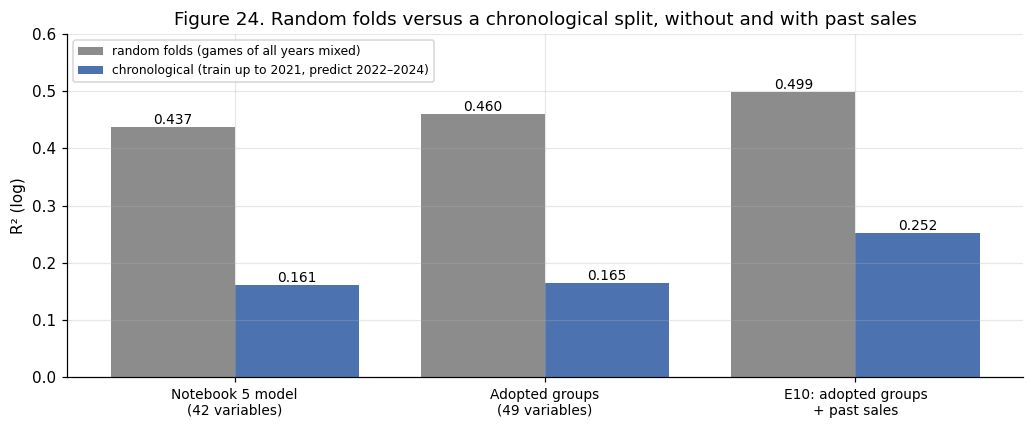

,Chronological R² (log),Chronological MAE (log),Chronological MAE (millions),For reference: random-fold CV R² (log)
Model,,,,
Notebook 5 model (42 variables),0.161,0.622,0.056,0.437
With adopted groups (49 variables),0.165,0.621,0.055,0.460
E10: adopted groups + past sales (53 variables),0.252,0.576,0.053,0.499


In [14]:
CUTOFF = pd.Timestamp("2021-12-31")
early = train[train["release_dt"] <= CUTOFF]
late = train[train["release_dt"] > CUTOFF]
print(f"Training-set games released up to 2021: {len(early):,} | released 2022 to June 2024: {len(late):,}")

SETS = [("Notebook 5 model (42 variables)", FEATURES),
        (f"With adopted groups ({len(adopted)} variables)", adopted),
        (f"E10: adopted groups + past sales ({len(adopted) + len(PAST_SALES)} variables)", adopted + PAST_SALES)]
rows = []
for name, features in SETS:
    _, pred = fit_predict(gradient_boosting, features, early, late)
    s = scores(late["owners"].to_numpy(), pred)
    random_cv, _ = cross_validate(gradient_boosting, features)
    rows.append({"Model": name, "Chronological R² (log)": s["R2 (log)"], "Chronological MAE (log)": s["MAE (log)"],
                 "Chronological MAE (millions)": s["MAE (millions)"],
                 "For reference: random-fold CV R² (log)": random_cv["R2 (log)"].mean()})
table33 = pd.DataFrame(rows).set_index("Model")
table33.to_csv(os.path.join(TAB_DIR, "table33_chronological_and_past_sales.csv"))

fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(table33))
for offset, column, color, label in [(-0.2, "For reference: random-fold CV R² (log)", GREY, "random folds (games of all years mixed)"),
                                     (0.2, "Chronological R² (log)", BLUE, "chronological (train up to 2021, predict 2022–2024)")]:
    ax.bar(x + offset, table33[column], 0.4, color=color, label=label)
    for xi, v in zip(x + offset, table33[column]):
        ax.text(xi, v + 0.006, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["Notebook 5 model\n(42 variables)", f"Adopted groups\n({len(adopted)} variables)",
                    "E10: adopted groups\n+ past sales"], fontsize=9)
ax.set_ylim(0, 0.6)
ax.set_ylabel("R² (log)")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Figure 24. Random folds versus a chronological split, without and with past sales")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig24_chronological_and_past_sales.png"), dpi=150, bbox_inches="tight")
plt.show()
table33.style.format("{:.3f}").set_caption(
    "Table 33. Gradient Boosting trained on releases up to 2021 and scored on releases from 2022 to June 2024 "
    "(training set only; the test set is not used)")

**Interpretation.**
- **Forecasting later years is much harder than the random split suggests.** Trained on releases up to 2021,
  the Notebook 5 model reaches R² (log) 0.161 on 2022–2024 releases, against 0.437 with random folds. Release
  year is the model's most important variable (Section 12.6) because older games have had longer to sell. For
  years after the training data ends, the model has no examples to learn that effect from.
- **The adopted groups add almost nothing on this split** (0.161 → 0.165). Their gain in Section 12.3 does not
  carry over to future releases.
- **Past sales add far more than any pre-release group (E10).** On the chronological split R² (log) rises from
  0.165 to 0.252 (+0.087) and MAE (log) falls from 0.621 to 0.576. With random folds the same variables give
  0.499 against 0.460.
- **This result is optimistic and is not adopted.** The past owner counts are read in 2025, so they include
  sales made after the game being predicted was released. A forecaster in 2022 would have seen smaller numbers.
  Past sales also exist for only 48.2% of games, because most games are a studio's first.
- **MAE in owners is lower here (0.055 million) only because recent games have fewer owners.** It should not
  be compared with the random-fold MAE.

## 12.6 Which variables matter in the adopted model

Permutation importance by group, as in Notebook 5 (Section 10.8): the drop in R² (log) on the validation
folds when all variables of a group are shuffled together.

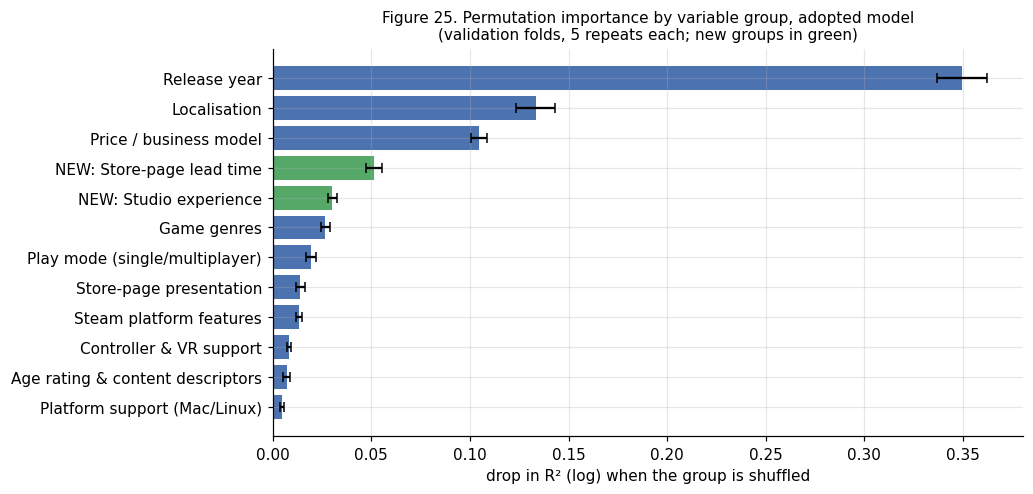

,Variables,Drop in R² (log) when shuffled,SD
Variable group,,,
Release year,1,0.350,0.013
Localisation,2,0.133,0.010
Price / business model,2,0.105,0.004
NEW: Store-page lead time,2,0.051,0.004
NEW: Studio experience,5,0.030,0.002
Game genres,11,0.027,0.002
Play mode (single/multiplayer),9,0.019,0.003
Store-page presentation,2,0.014,0.002
Steam platform features,5,0.013,0.002


In [15]:
FEATURE_GROUPS = {
    "Price / business model": ["price", "genre_Free_To_Play"],
    "Release year": ["release_year"],
    "Localisation": ["n_languages", "n_audio_languages"],
    "Platform support (Mac/Linux)": ["mac", "linux"],
    "Store-page presentation": ["n_screenshots", "description_length"],
    "Age rating & content descriptors": ["required_age", "genre_Violent", "genre_Gore", "genre_Nudity"],
    "Game genres": ["genre_Indie", "genre_Casual", "genre_Action", "genre_Adventure", "genre_Simulation",
                    "genre_Strategy", "genre_RPG", "genre_Sports", "genre_Racing", "genre_Massively_Multiplayer",
                    "genre_Education"],
    "Play mode (single/multiplayer)": ["cat_Single_player", "cat_Multi_player", "cat_PvP", "cat_Co_op",
                                       "cat_Online_PvP", "cat_Online_Co_op", "cat_Shared_Split_Screen",
                                       "cat_Shared_Split_Screen_PvP", "cat_Shared_Split_Screen_Co_op"],
    "Controller & VR support": ["cat_Full_controller_support", "cat_Partial_Controller_Support",
                                "cat_Tracked_Controller_Support", "cat_VR_Only"],
    "Steam platform features": ["cat_Steam_Cloud", "cat_Steam_Leaderboards", "cat_Stats",
                                "cat_Includes_level_editor", "cat_Captions_available"],
}
for group in adopted_groups:
    FEATURE_GROUPS[f"NEW: {group[3:]}"] = GROUPS[group]
assert sorted(c for cols in FEATURE_GROUPS.values() for c in cols) == sorted(adopted)

y_log = np.log1p(train["owners"].to_numpy())
drops = {g: [] for g in FEATURE_GROUPS}
for i, (tr, va) in enumerate(folds):
    fitted, pred = fit_predict(gradient_boosting, adopted, train.iloc[tr], train.iloc[va])
    base_r2 = r2_score(y_log[va], pred)
    rng = np.random.default_rng(RANDOM_STATE + i)
    X_va = train.iloc[va][adopted]
    for g, cols in FEATURE_GROUPS.items():
        for _ in range(5):
            shuffled = X_va.copy()
            shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(shuffled))]
            drops[g].append(base_r2 - r2_score(y_log[va], fitted.predict(shuffled)))
table34 = pd.DataFrame({"Variables": {g: len(c) for g, c in FEATURE_GROUPS.items()},
                        "Drop in R² (log) when shuffled": {g: np.mean(d) for g, d in drops.items()},
                        "SD": {g: np.std(d, ddof=1) for g, d in drops.items()}})
table34 = table34.sort_values("Drop in R² (log) when shuffled", ascending=False)
table34.index.name = "Variable group"
table34.to_csv(os.path.join(TAB_DIR, "table34_new_variables_importance.csv"))

fig, ax = plt.subplots(figsize=(9.5, 4.6))
t = table34.iloc[::-1]
ax.barh(t.index, t["Drop in R² (log) when shuffled"], xerr=t["SD"], capsize=3,
        color=[GREEN if g.startswith("NEW") else BLUE for g in t.index])
ax.set_xlabel("drop in R² (log) when the group is shuffled")
ax.set_title("Figure 25. Permutation importance by variable group, adopted model\n"
             "(validation folds, 5 repeats each; new groups in green)", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig25_new_variables_importance.png"), dpi=150, bbox_inches="tight")
plt.show()
table34.style.format({"Drop in R² (log) when shuffled": "{:.3f}", "SD": "{:.3f}"}).set_caption(
    "Table 34. Permutation importance by variable group (adopted model, validation folds)")

**Interpretation.**
- **The two adopted groups rank fourth and fifth of twelve.** Shuffling store-page lead time costs 0.052 R²
  and studio experience 0.030, both more than the eleven genre variables together (0.027).
- **The three leading groups are unchanged from Notebook 5:** release year (0.350), localisation (0.133) and
  price and business model (0.105). Release year alone costs more than localisation and price together, which
  is the weakness the chronological split exposes.

## 12.7 Paid and free-to-play games: accuracy and percentage effects

Following the second parent paper's approach (Notebook 6), accuracy is reported separately for paid and
free-to-play games, and the adopted new variables are reported as percentage effects from separate
log-linear models. The models are those of Notebook 6 (Section 11.2) with the new variables added in banded
form.

In [16]:
is_free = (train["price"] == 0).to_numpy()
rows = []
for name, oof in [("Notebook 5 model (42 variables)", reference_oof),
                  (f"With adopted groups ({len(adopted)} variables)", adopted_oof)]:
    rows.append({"Model": name, "R² (log), all games": r2_score(y_log, oof),
                 "R² (log), paid": r2_score(y_log[~is_free], oof[~is_free]),
                 "R² (log), free-to-play": r2_score(y_log[is_free], oof[is_free]),
                 "MAE (log), paid": mean_absolute_error(y_log[~is_free], oof[~is_free]),
                 "MAE (log), free-to-play": mean_absolute_error(y_log[is_free], oof[is_free])})
table35 = pd.DataFrame(rows).set_index("Model")
table35.to_csv(os.path.join(TAB_DIR, "table35_new_variables_paid_vs_free.csv"))
table35.style.format("{:.3f}").set_caption(
    f"Table 35. Out-of-fold accuracy for paid ({(~is_free).sum():,}) and free-to-play ({is_free.sum():,}) training games")

,"R² (log), all games","R² (log), paid","R² (log), free-to-play","MAE (log), paid","MAE (log), free-to-play"
Model,,,,,
Notebook 5 model (42 variables),0.437,0.438,0.400,0.627,0.850
With adopted groups (49 variables),0.460,0.461,0.422,0.609,0.839


In [17]:
def ols(frame, columns):
    """OLS of log(owners) on `columns` (Notebook 6). Coefficients are converted to percentage effects,
    100 × (exp(b) − 1), with 95% confidence intervals and two-sided p-values."""
    X = np.column_stack([np.ones(len(frame))] + [frame[c].astype(float).to_numpy() for c in columns])
    y = np.log(frame["owners"].to_numpy())
    xtx_inv = np.linalg.pinv(X.T @ X)
    beta = xtx_inv @ X.T @ y
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    se = np.sqrt(np.diag(resid @ resid / dof * xtx_inv))
    t_crit = stats.t.ppf(0.975, dof)
    out = pd.DataFrame({"variable": ["(intercept)"] + list(columns), "coef": beta,
                        "p_value": 2 * stats.t.sf(np.abs(beta / se), dof)}).set_index("variable")
    out["effect (%)"] = 100 * (np.exp(out["coef"]) - 1)
    out["CI low (%)"] = 100 * (np.exp(out["coef"] - t_crit * se) - 1)
    out["CI high (%)"] = 100 * (np.exp(out["coef"] + t_crit * se) - 1)
    return out, 1 - resid @ resid / ((y - y.mean()) @ (y - y.mean()))


# Notebook 6's specification
GENRES = ["genre_Action", "genre_Adventure", "genre_RPG", "genre_Simulation", "genre_Strategy",
          "genre_Sports", "genre_Casual", "genre_Indie", "genre_Massively_Multiplayer", "genre_Racing"]
STORE_PAGE = ["n_languages", "n_audio_languages", "n_screenshots", "description_length_1000"]
PLATFORM_PLAY = ["mac", "linux", "required_age", "cat_Single_player", "cat_Multi_player", "cat_Online_PvP",
                 "cat_Online_Co_op", "cat_Full_controller_support", "cat_VR_Only"]
BAND_EDGES = [0.0, 10, 20, 30, 40, 60, 80, np.inf]
BAND_LABELS = ["$0.99–9.99", "$10–19.99", "$20–29.99", "$30–39.99", "$40–59.99", "$60–79.99", "$80+"]

frame = data.copy()
frame["description_length_1000"] = frame["description_length"] / 1000
price_band = pd.cut(frame["price"], BAND_EDGES, labels=BAND_LABELS, right=False)
for b in BAND_LABELS[1:]:
    frame[f"price_{b}"] = ((price_band == b) & (frame["price"] > 0)).astype(int)

# The adopted new variables in banded form, so that each effect reads as a percentage
NEW_EFFECTS = {
    "Developer has 1–2 earlier releases": frame["Developer's earlier releases"] == "1–2",
    "Developer has 3–9 earlier releases": frame["Developer's earlier releases"] == "3–9",
    "Developer has 10 or more earlier releases": frame["Developer's earlier releases"] == "10 or more",
    "Self-published": frame["self_published"] == 1,
    "Lead time 1–6 months": frame["Store-page lead time"] == "1–6 months",
    "Lead time 6–12 months": frame["Store-page lead time"] == "6–12 months",
    "Lead time 1–2 years": frame["Store-page lead time"] == "1–2 years",
    "Lead time 2 years or more": frame["Store-page lead time"] == "2 years or more",
    "Lead time missing": frame["lead_missing"] == 1,
}
for name, flag in NEW_EFFECTS.items():
    frame[name] = flag.astype(int)

effects, r2_in_sample = {}, {}
for seg, part in [("Paid", frame[frame["price"] > 0]), ("Free-to-play", frame[frame["price"] == 0])]:
    years = pd.DataFrame({f"year_{y}": (part["release_year"] == y).astype(int)
                          for y in sorted(part["release_year"].unique())
                          if y != 2020 and (part["release_year"] == y).sum() >= 30}, index=part.index)
    part = pd.concat([part, years], axis=1)
    columns = ([f"price_{b}" for b in BAND_LABELS[1:]] if seg == "Paid" else []) \
        + [g for g in GENRES if part[g].sum() >= 30] + STORE_PAGE + PLATFORM_PLAY + list(years.columns)
    _, r2_before = ols(part, columns)
    effects[seg], r2_in_sample[seg] = ols(part, list(NEW_EFFECTS) + columns)
    print(f"{seg}: {len(part):,} games | in-sample R² {r2_before:.3f} without the new variables, "
          f"{r2_in_sample[seg]:.3f} with them")

rows = []
for name in NEW_EFFECTS:
    row = {"Variable": name}
    for seg in ["Paid", "Free-to-play"]:
        r = effects[seg].loc[name]
        row[f"{seg}: effect [95% CI]"] = f"{r['effect (%)']:+.1f}% [{r['CI low (%)']:+.1f}, {r['CI high (%)']:+.1f}]"
        row[f"{seg}: p"] = "<0.001" if r["p_value"] < 0.001 else f"{r['p_value']:.3f}"
    rows.append(row)
table36 = pd.DataFrame(rows).set_index("Variable")
pd.concat([effects[s].loc[list(NEW_EFFECTS)].assign(segment=s) for s in effects]) \
    .to_csv(os.path.join(TAB_DIR, "table36_new_variables_percentage_effects.csv"))
table36.style.set_caption("Table 36. Percentage effects of the adopted new variables on owners (log-linear OLS as in "
                          "Notebook 6; reference: developer's first game, separate publisher, lead time under 1 month)")

Paid: 68,380 games | in-sample R² 0.316 without the new variables, 0.337 with them
Free-to-play: 8,347 games | in-sample R² 0.288 without the new variables, 0.306 with them


,Paid: effect [95% CI],Paid: p,Free-to-play: effect [95% CI],Free-to-play: p
Variable,,,,
Developer has 1–2 earlier releases,"+9.1% [+7.1, +11.2]",<0.001,"+9.4% [+2.0, +17.3]",0.012
Developer has 3–9 earlier releases,"+15.8% [+13.2, +18.6]",<0.001,"+31.3% [+17.5, +46.7]",<0.001
Developer has 10 or more earlier releases,"+3.9% [+1.0, +6.9]",0.008,"+58.3% [+29.9, +93.0]",<0.001
Self-published,"-16.3% [-17.6, -14.9]",<0.001,"-14.1% [-19.1, -8.9]",<0.001
Lead time 1–6 months,"+5.3% [+3.4, +7.2]",<0.001,"+13.7% [+6.9, +20.9]",<0.001
Lead time 6–12 months,"+18.6% [+15.6, +21.6]",<0.001,"+28.4% [+17.0, +40.9]",<0.001
Lead time 1–2 years,"+36.9% [+33.1, +40.8]",<0.001,"+46.6% [+31.6, +63.2]",<0.001
Lead time 2 years or more,"+74.3% [+68.7, +80.2]",<0.001,"+98.2% [+74.6, +125.0]",<0.001
Lead time missing,"+17.9% [+6.1, +31.1]",0.002,"+31.5% [-13.4, +99.6]",0.198


**Interpretation.**
- **Both segments gain about the same** (Table 35): paid games from 0.438 to 0.461, free-to-play games from
  0.400 to 0.422. Free-to-play games remain harder to predict.
- **Lead time has the largest effects, rising at every step (Table 36).** With genre, price, store page and
  release year held fixed, a page online two years or more goes with +74% owners for paid games and +98% for
  free-to-play games, relative to under a month. Part of this may come from Early Access games, which can sell
  for a long time before their recorded release date.
- **Developer experience matters more for free-to-play games.** Developers with 10 or more earlier releases
  have +58% owners there (95% CI +30% to +93%), against +4% for paid games. With 3–9 earlier releases the
  effects are +31% and +16%.
- **Self-published games have fewer owners in both segments:** −16% for paid and −14% for free-to-play games.
- **In-sample R² rises** from 0.316 to 0.337 (paid) and from 0.288 to 0.306 (free-to-play).
- As in Notebook 6, these are associations. A long lead time and a separate publisher both go with larger
  budgets, which the data do not show.

---
## 12.8 Findings and decision

**Findings.**
1. **Two of four new groups improve the model.** Studio experience (+0.013) and store-page lead time (+0.010)
   pass the adoption rule. Franchise and title (+0.001) and store-page extras (−0.001) do not.
2. **The adopted model reaches cross-validated R² (log) 0.460 and test R² (log) 0.446**, against 0.437 and
   0.426 in Notebook 5. The gain is modest and survives grouping the folds by title.
3. **Lead time is the most informative new variable.** It ranks fourth among all variable groups, and it is the
   closest available substitute for the second parent paper's wishlist counts.
4. **Random folds overstate forecasting accuracy.** On releases after the training period, R² (log) is 0.165,
   not 0.460, and the new groups do not help there.
5. **A studio's past sales would help the most (0.165 → 0.252 on the chronological split)**, but in this
   dataset they are a 2025 snapshot and partly include the future, so the result is optimistic.
6. **All effects are associations, not causes.** Useful relationships also do not mean accurate predictions
   for a single game: the typical error is still a factor of about 1.5 to 2 in owners.

**Decision.**
- **Reference model:** Gradient Boosting on log1p(owners) with 49 variables (the 42 of Notebook 1, studio
  experience and store-page lead time).
- **Not adopted:** franchise and title, store-page extras, and past sales.
- **Reporting:** the chronological R² is reported next to the random-fold R² from now on.

**Next steps.**
1. Reduce the dependence on release year, for example by predicting owners relative to games released in the
   same year, so that the model can forecast years it has not seen.
2. Find past-sales information dated before each release, which would make the E10 result usable.
3. Tune Gradient Boosting with nested cross-validation.